# A/B Testing Case Study: Landing Page Call-to-Action Button

This notebook walks through a complete A/B test from **experiment design** through **results analysis**, in the two stages a data scientist would actually work through on the job:

- **Part 1 — Experiment Design (pre-data).** Before any data exists, we define the business and statistical hypotheses, agree on the primary metric, determine the randomization unit, run a power analysis to size the test, and describe how the data would actually get collected in a real organization.
- **Part 2 — Results Analysis (post-data).** We choose and justify a statistical test, evaluate statistical and practical significance, and draw a business conclusion.

**A note on the data:** no real experiment was run for this project. To demonstrate the full workflow end-to-end, the dataset (`ab_test_click_data.csv`) is synthetically generated in Part 1, using the sample size the power analysis says we'd need. This is stated transparently throughout — the goal is to demonstrate the design and analysis process, not to claim a real product result.

**Skills demonstrated:** hypothesis formulation, power analysis, experiment design trade-offs, data validation, statistical test selection (z-test vs. t-test vs. chi-square vs. non-parametric alternatives), significance testing, confidence intervals, and practical significance / business decision-making.

## Part 1 — Experiment Design

> At this point in the project, **no data exists yet**. Everything below is scoped the way it would be before an experiment ever launches: business framing, hypotheses, metric selection, sample size, and the data collection process. The dataset used in Part 2 is generated at the end of Part 1, standing in for what a real experiment pipeline would eventually produce.

### Business Context

![diagram](control_experimental.png)

A mid-sized SaaS company's landing page currently uses a **Secure Free Trial** button (the **Control** version). The growth team has proposed a new **Enroll Now** button (the **Experimental** version), hypothesizing that more action-oriented language will drive more clicks. Users are randomly split between the two versions when they land on the page; those who see the existing button are the **control group**, and those who see the new button are the **experimental group**.

The business question: **should the company replace the existing button with the new one?**

### Primary Metric (Overall Evaluation Criterion)

We use **Click-Through Rate (CTR)** — the proportion of users who click the button — as the primary metric (OEC). CTR is a standard, well-understood engagement metric, is directly attributable to the button change (nothing else on the page differs between arms), and can be measured over a short window, making it well suited to this test.

### Business Hypothesis

**We believe the "Enroll Now" button will increase CTR by at least 3 percentage points, from a baseline of ≈15% to ≈18%** (a 20% relative lift). This absolute gap is the **Minimum Detectable Effect (MDE)** — the smallest improvement, decided upfront rather than after seeing results, that would actually be worth the engineering cost and risk of a full rollout.

### Statistical Hypothesis

In plain terms: the **null hypothesis** is that the new button makes no real difference to CTR — any gap we observe is just noise. The **alternative hypothesis** is that the two buttons' true CTRs are actually different. Formally, letting $p_{con}$ and $p_{exp}$ denote the true (population) click-through rates for the control and experimental groups:

$$
\begin{cases}
H_0 : p_{con} = p_{exp} \\
H_1 : p_{con} \neq p_{exp}
\end{cases}
$$

A **two-sided test** is used because, in principle, the new button could perform worse than the old one — we don't want to rule that out a priori.

### Randomization Unit & Data Requirements

The **unit of randomization is the `user_id`**: each unique visitor is randomly assigned to either the control or experimental arm the first time they land on the page, and stays in that arm for the duration of the test (a "sticky" assignment). This is the natural choice here because we care about individual click behavior, not session- or page-view-level behavior, and randomizing at the session level would let the same user see both variants, contaminating the comparison.

Key design assumptions (SUTVA — Stable Unit Treatment Value Assumption):
- One user's assignment and behavior doesn't affect another user's outcome (no network/social interference).
- A user is exposed to exactly one variant for the full test duration.

**Data required per user, at minimum:**

| Field | Description |
|---|---|
| `user_id` | Unique visitor identifier |
| `group` | Assigned arm (`con` / `exp`) |
| `click` | Whether the button was clicked (1/0) |
| `timestamp` | When the event occurred |

### Data Collection Process

Before this test could actually run, a few things would need to happen — for a portfolio project this is simulated, but in practice this stage takes real coordination:

- **Stakeholder alignment.** Product and growth leadership agree on CTR as the OEC, sign off on the 3pp absolute MDE (20% relative) as the bar for a "worthwhile" launch, and agree on a decision rule (ship if statistically *and* practically significant, hold otherwise).
- **Engineering collaboration.** Front-end/engineering implement the button variant and wire up click-event logging to the analytics pipeline; an experiment-assignment service (or feature-flagging tool) handles the actual traffic split and guarantees sticky, mutually-exclusive assignment with any other concurrently running experiments.
- **QA / pre-launch checks.** Before trusting any results, teams commonly run an **A/A test** (splitting traffic but showing everyone the same button) to confirm the randomization and logging pipeline are unbiased, and confirm the two arms differ *only* in button copy — no other confounded change ships alongside it.
- **Data ownership.** Data engineering agrees on the event schema (the four fields above) and owns the pipeline that lands raw events into a queryable table — this is the schema the simulated dataset below is built to match.
- **Monitoring while live.** During the test, the team watches for **Sample Ratio Mismatch (SRM)** — a sign the randomization is broken if the observed group split deviates from the intended one — and any guardrail metrics (e.g., page load time, downstream conversion) to catch unintended harm before the test concludes. This is not the same as "peeking": SRM checks the health of the randomization mechanism itself rather than the treatment effect, and guardrail monitoring exists to catch harm, not to decide early that the new button has "won" — repeatedly checking the *primary metric's* p-value and stopping as soon as it looks significant is what actually inflates the false-positive rate, and is exactly what the pre-registered MDE and sample size in this design are meant to guard against.

### Sample Size & Test Duration — Power Analysis

Before launch we need to decide how many users to include in each arm. This is determined through **power analysis**, which depends on:

- **Significance level ($\alpha$)** — probability of a Type I error (false positive). Industry-standard **5%**.
- **Power ($1-\beta$)** — probability of detecting a true effect if one exists. Industry-standard **80%**, i.e. a 20% Type II error rate ($\beta$).
- **Effect size** — derived from the two absolute proportions being compared: baseline CTR (15%) and target CTR (18%), i.e. the same 3pp absolute MDE introduced above (20% relative), expressed the way the sample-size formula actually consumes it — `proportion_effectsize` takes two proportions, not a relative percentage.

Too small a sample risks missing a real effect; too large wastes time and exposes more users to an unproven change than necessary.

In [1]:
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.stats.api as sms
from scipy.stats import norm

%matplotlib inline

In [2]:
# Design parameters, agreed with stakeholders before the test is run
alpha = 0.05          # significance level
power = 0.80          # desired power (1 - beta)

p_con_baseline = 0.15       # current CTR of the "Secure Free Trial" button
mde_relative = 0.20         # relative lift equivalent to the absolute MDE below (for reference)
p_exp_target = p_con_baseline * (1 + mde_relative)   # target CTR of "Enroll Now"
mde_absolute = p_exp_target - p_con_baseline

print(f"Baseline CTR (control):        {p_con_baseline:.1%}")
print(f"Target CTR (experimental):     {p_exp_target:.1%}")
print(f"Minimum Detectable Effect:     {mde_absolute:.1%} absolute (≈{mde_relative:.0%} relative)")

# Effect size for two independent proportions
effect_size = sms.proportion_effectsize(p_con_baseline, p_exp_target)
print(f"\nEffect size (Cohen's h): {effect_size:.4f}")

# Required sample size per group, assuming equal-sized arms
required_n = sms.NormalIndPower().solve_power(
    effect_size,
    power=power,
    alpha=alpha,
    ratio=1,
)
required_n = ceil(required_n)

print(f"Required sample size per group: {required_n:,}")
print(f"Total required sample size:     {required_n * 2:,}")

Baseline CTR (control):        15.0%
Target CTR (experimental):     18.0%
Minimum Detectable Effect:     3.0% absolute (≈20% relative)

Effect size (Cohen's h): -0.0809
Required sample size per group: 2,399
Total required sample size:     4,798


**Translating sample size into test duration.** Sample size alone doesn't tell us how long the test needs to run — that depends on how much traffic the landing page actually gets. Suppose analytics reports the page averages **400 unique visitors/day**, split 50/50 across the two arms (200/day per arm).

In [3]:
# Traffic assumption, agreed with the analytics team
daily_visitors_per_group = 200

test_duration_days = ceil(required_n / daily_visitors_per_group)

print(f"Assumed traffic per group: {daily_visitors_per_group}/day")
print(f"Estimated test duration:   {test_duration_days} days (~{ceil(test_duration_days / 7)} weeks)")

Assumed traffic per group: 200/day
Estimated test duration:   12 days (~2 weeks)


### From Design to Data

At this point, in a real organization, the test would launch and run for the number of days computed above while engineering's instrumentation logs click events to the schema agreed earlier, with the team monitoring for Sample Ratio Mismatch and guardrail regressions along the way.

**Since no real experiment was run for this project, we simulate the outcome of this exact design** — same sample size, same schema — using a Python data-generating process. This stands in for the real experiment pipeline described in the Data Collection Process section. To keep the simulation both grounded in the design and realistic, we generate data with a true experimental CTR modestly above the target the business set (18% target → 19% simulated true rate), rather than landing exactly on the MDE boundary.

In [4]:
np.random.seed(42)

# Buffer above the minimum required sample size, representing a few extra days of traffic
buffer_days = 3
n_per_group = required_n + buffer_days * daily_visitors_per_group

# True click probabilities used to simulate the experiment outcome. We simulate the
# experimental CTR slightly above the target (target 18%, simulated true 19%) to represent
# a plausible real-world scenario where the change performs a bit better than the minimum
# bar stakeholders set — rather than landing exactly on the MDE boundary, which would make
# the practical-significance call a coin flip driven by sampling noise alone.
p_click_con_true = p_con_baseline
p_click_exp_true = p_exp_target + 0.01

groups = np.array(['con'] * n_per_group + ['exp'] * n_per_group)
clicks_con = np.random.binomial(1, p_click_con_true, size=n_per_group)
clicks_exp = np.random.binomial(1, p_click_exp_true, size=n_per_group)
clicks = np.concatenate([clicks_con, clicks_exp])

n_total = n_per_group * 2
timestamps = pd.date_range(start="2024-01-01 00:00:00", periods=n_total, freq="min")

df_ab_test = pd.DataFrame({
    'user_id': np.arange(1, n_total + 1),
    'group': groups,
    'click': clicks,
    'timestamp': timestamps,
})

df_ab_test.to_csv('ab_test_click_data.csv', index=False)

print(f"Simulated {n_total:,} users ({n_per_group:,} per group)")
df_ab_test.head()

Simulated 5,998 users (2,999 per group)


,user_id,group,click,timestamp
0,1,con,0,2024-01-01 00:00:00
1,2,con,1,2024-01-01 00:01:00
2,3,con,0,2024-01-01 00:02:00
3,4,con,0,2024-01-01 00:03:00
4,5,con,0,2024-01-01 00:04:00


### Data Cleaning & Sanity Checks

Before analyzing results, an analyst would run the same validation checks on real exported data that we run here — this is the practical follow-through on the "QA / monitoring" points raised in the Data Collection Process section.

In [5]:
# 1. Missing values
print("Missing values per column:")
print(df_ab_test.isna().sum())

# 2. Duplicate users (a user should appear exactly once)
duplicate_users = df_ab_test['user_id'].duplicated().sum()
print(f"\nDuplicate user_id rows: {duplicate_users}")

# 3. Every user assigned to exactly one group (mutually exclusive assignment)
users_per_group_count = df_ab_test.groupby('user_id')['group'].nunique()
multi_group_users = (users_per_group_count > 1).sum()
print(f"Users assigned to more than one group: {multi_group_users}")

# 4. Sample Ratio Mismatch (SRM) check — observed split vs. intended 50/50 split
#
# H0: users were assigned con/exp in a true 50/50 split (randomization is healthy)
# H1: the split differs from 50/50 by more than chance (randomization/logging is broken)
#
# We use alpha = 0.01 here (stricter than the 0.05 used for the CTR test later), since this
# check effectively runs on every experiment and a looser threshold would trigger false
# alarms on ~1-in-20 healthy tests.
from scipy.stats import chisquare

group_counts = df_ab_test['group'].value_counts()
expected_counts = [group_counts.sum() / 2, group_counts.sum() / 2]
srm_chi2, srm_p_value = chisquare(group_counts, f_exp=expected_counts)

srm_alpha = 0.01
print(f"\nObserved group split: con={group_counts['con']:,}, exp={group_counts['exp']:,}")
print(f"SRM chi-square p-value: {srm_p_value:.3f} vs. alpha: {srm_alpha}")
print("Fail to reject H0 -> SRM check passed: no evidence the randomization pipeline is broken."
      if srm_p_value > srm_alpha else
      "Reject H0 -> SRM check FAILED: split deviates from 50/50 more than chance would explain — investigate the assignment pipeline before trusting results.")

print(f"\nDataset shape: {df_ab_test.shape}")
print(f"Date range: {df_ab_test['timestamp'].min()} to {df_ab_test['timestamp'].max()}")

Missing values per column:
user_id      0
group        0
click        0
timestamp    0
dtype: int64

Duplicate user_id rows: 0
Users assigned to more than one group: 0

Observed group split: con=2,999, exp=2,999
SRM chi-square p-value: 1.000 vs. alpha: 0.01
Fail to reject H0 -> SRM check passed: no evidence the randomization pipeline is broken.

Dataset shape: (5998, 4)
Date range: 2024-01-01 00:00:00 to 2024-01-05 03:57:00


### Data Description

With the data validated, here's a quick look at what we're working with before moving into formal analysis in Part 2.

In [6]:
summary = df_ab_test.groupby('group').agg(
    user_count=('user_id', 'count'),
    total_clicks=('click', 'sum'),
    ctr=('click', 'mean'),
)
summary

,user_count,total_clicks,ctr
group,,,
con,2999,458,0.152718
exp,2999,557,0.185729


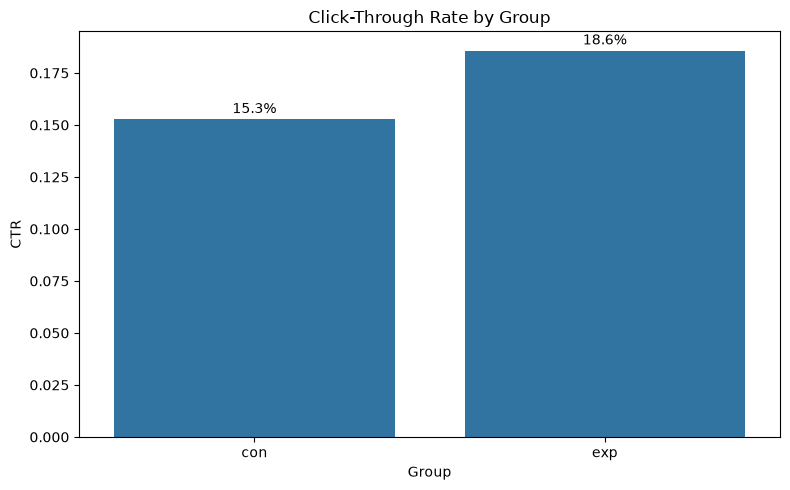

In [7]:
plt.figure(figsize=(8, 5))
sns.barplot(x=summary.index, y=summary['ctr'])
plt.title('Click-Through Rate by Group')
plt.xlabel('Group')
plt.ylabel('CTR')
for i, ctr in enumerate(summary['ctr']):
    plt.text(i, ctr + 0.003, f'{ctr:.1%}', ha='center')
plt.tight_layout()
plt.show()

The experimental group ("Enroll Now") shows a higher observed CTR (18.6%) than the control group ("Secure Free Trial", 15.3%) — a gap we test for statistical and practical significance next.

## Part 2 — Results Analysis

With the (simulated) experiment data collected and validated, we now move into the analysis phase: choosing the right statistical test, checking significance, and translating the result into a business decision.

**Recap of what we're testing:**

$$
\begin{cases}
H_0 : p_{con} = p_{exp} \\
H_1 : p_{con} \neq p_{exp}
\end{cases}
\qquad \alpha = 0.05 \qquad \text{MDE} = 3\text{pp absolute} \ (\approx 20\% \text{ relative})
$$

### Choosing the Right Statistical Test

CTR is a **binary outcome** (click / no click) aggregated into a **proportion** per group, which narrows down the reasonable options considerably:

| Test | When it applies | Applicable here? |
|---|---|---|
| **Two-sample z-test for proportions** | Comparing two independent proportions/rates, large sample size | ✅ Yes — this is exactly our setup |
| **Two-sample t-test** | Comparing means of a *continuous* variable across two groups | ❌ CTR is binary, not continuous — would apply if comparing e.g. average time-on-page instead |
| **Chi-square test of independence** | Testing association between two categorical variables (e.g. group × click) | ⚠️ Would give an equivalent result to the two-sided z-test here (chi-square with 1 dof is mathematically equivalent to a two-sided z-test on two proportions), but the z-test is preferred because it directly yields a signed effect size, a confidence interval on the *difference*, and supports one-sided tests |
| **Mann-Whitney U / non-parametric tests** | Comparing distributions of a continuous/ordinal variable when normality doesn't hold | ❌ Not applicable to a binary outcome; useful for secondary numeric metrics (e.g. session duration) that are skewed |

**Why the z-test is valid here, via the Central Limit Theorem:** each group's click outcomes are i.i.d. Bernoulli trials. By the CLT, the sample proportion $\hat{p}$ is approximately normally distributed once the sample size is reasonably large — the standard rule of thumb is $np \geq 10$ and $n(1-p) \geq 10$ for both groups. We check that below rather than just asserting it.

Unlike a continuous metric, a binary proportion doesn't need — or have — a meaningful normality/variance check on the raw data itself (Shapiro-Wilk, Levene's test, etc. are built for continuous variables). Those checks matter when the *outcome itself* is numeric and skewed (e.g. revenue, time-on-page) — worth knowing when to reach for them, and knowing they're the wrong tool here.

In [8]:
# Check the CLT rule-of-thumb (np >= 10 and n(1-p) >= 10) for both groups
for grp in ['con', 'exp']:
    n_grp = (df_ab_test['group'] == grp).sum()
    p_grp = df_ab_test.loc[df_ab_test['group'] == grp, 'click'].mean()
    np_check = n_grp * p_grp
    n1p_check = n_grp * (1 - p_grp)
    print(f"Group '{grp}': n={n_grp:,}, p={p_grp:.3f} -> n*p={np_check:.0f}, n*(1-p)={n1p_check:.0f} "
          f"({'OK' if np_check >= 10 and n1p_check >= 10 else 'FAILS rule of thumb'})")

Group 'con': n=2,999, p=0.153 -> n*p=458, n*(1-p)=2541 (OK)
Group 'exp': n=2,999, p=0.186 -> n*p=557, n*(1-p)=2442 (OK)


Both groups clear the $np \geq 10$ and $n(1-p) \geq 10$ rule of thumb, so the normal approximation holds and we proceed with the two-sample z-test for proportions.

### Statistical Significance Test

We compute the pooled proportion (assuming $H_0$ is true), its standard error, the z-statistic, and the resulting p-value.

In [9]:
# Observed counts
X_con = int(df_ab_test.loc[df_ab_test['group'] == 'con', 'click'].sum())
X_exp = int(df_ab_test.loc[df_ab_test['group'] == 'exp', 'click'].sum())
N_con = int((df_ab_test['group'] == 'con').sum())
N_exp = int((df_ab_test['group'] == 'exp').sum())

# Sample proportions
p_con_hat = X_con / N_con
p_exp_hat = X_exp / N_exp

# Pooled proportion (under H0: p_con = p_exp)
p_pooled_hat = (X_con + X_exp) / (N_con + N_exp)

# Pooled standard error
pooled_variance = p_pooled_hat * (1 - p_pooled_hat) * (1 / N_con + 1 / N_exp)
SE = np.sqrt(pooled_variance)

# Test statistic and two-sided p-value
z_stat = (p_exp_hat - p_con_hat) / SE
z_crit = norm.ppf(1 - alpha / 2)
p_value = 2 * norm.sf(abs(z_stat))

print(f"Control CTR:        {p_con_hat:.4f}")
print(f"Experimental CTR:   {p_exp_hat:.4f}")
print(f"Pooled CTR:         {p_pooled_hat:.4f}")
print(f"Standard error:     {SE:.5f}")
print(f"Z-statistic:        {z_stat:.3f}")
print(f"Z-critical (95%):   {z_crit:.3f}")
print(f"P-value:            {p_value:.4g}")

Control CTR:        0.1527
Experimental CTR:   0.1857
Pooled CTR:         0.1692
Standard error:     0.00968
Z-statistic:        3.409
Z-critical (95%):   1.960
P-value:            0.0006514


**Note:** the z-test above is computed manually (pooled proportion → SE → z-statistic) to make the mechanics explicit. In practice, `statsmodels.stats.proportion.proportions_ztest` performs the same pooled-proportion z-test in one call — we verify below that it agrees with the manual result.

In [10]:
from statsmodels.stats.proportion import proportions_ztest

z_stat_sm, p_value_sm = proportions_ztest([X_exp, X_con], [N_exp, N_con])

print(f"statsmodels z-statistic: {z_stat_sm:.3f} (manual: {z_stat:.3f})")
print(f"statsmodels p-value:     {p_value_sm:.4g} (manual: {p_value:.4g})")

statsmodels z-statistic: 3.409 (manual: 3.409)
statsmodels p-value:     0.0006514 (manual: 0.0006514)


#### Visualizing the Test Statistic vs. the Rejection Region

To make the decision above intuitive, we plot the standard normal distribution with the two-sided rejection region shaded, alongside where our observed z-statistic actually falls.

#### Checking Statistical Significance

With the z-statistic and p-value computed above, we now compare the p-value against $\alpha = 0.05$ to decide whether to reject $H_0$.

In [11]:
def is_statistically_significant(p_value, alpha):
    """
    Assess statistical significance of an A/B test result based on the p-value and alpha.

    Arguments:
    - p_value (float): The p-value from the statistical test
    - alpha (float): The significance level threshold

    Returns:
    - bool: True if the result is statistically significant
    """
    significant = p_value <= alpha
    print(f"P-value: {p_value:.4g} vs. alpha: {alpha}")
    if significant:
        print(
            "Reject H0: there is statistically significant evidence that the CTR\n"
            "of the 'Enroll Now' button differs from the 'Secure Free Trial' button."
        )
    else:
        print(
            "Fail to reject H0: not enough statistically significant evidence\n"
            "that the two versions' CTRs differ."
        )
    return significant


is_significant = is_statistically_significant(p_value, alpha)

P-value: 0.0006514 vs. alpha: 0.05
Reject H0: there is statistically significant evidence that the CTR
of the 'Enroll Now' button differs from the 'Secure Free Trial' button.


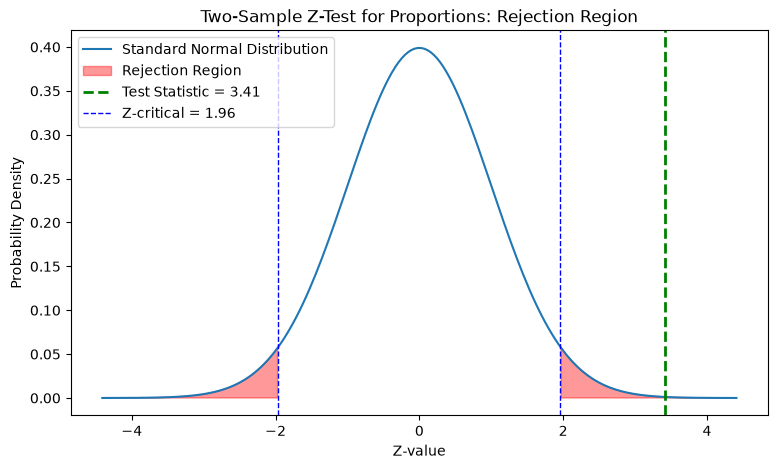

In [12]:
x_max = max(4, abs(z_stat) + 1)
x = np.linspace(-x_max, x_max, 200)
y = norm.pdf(x)

plt.figure(figsize=(9, 5))
plt.plot(x, y, label='Standard Normal Distribution')
plt.fill_between(x, y, where=(x > z_crit) | (x < -z_crit), color='red', alpha=0.4, label='Rejection Region')
plt.axvline(z_stat, color='green', linestyle='dashed', linewidth=2, label=f'Test Statistic = {z_stat:.2f}')
plt.axvline(z_crit, color='blue', linestyle='dashed', linewidth=1, label=f'Z-critical = {z_crit:.2f}')
plt.axvline(-z_crit, color='blue', linestyle='dashed', linewidth=1)
plt.xlabel('Z-value')
plt.ylabel('Probability Density')
plt.title('Two-Sample Z-Test for Proportions: Rejection Region')
plt.legend()
plt.show()

The test statistic (z ≈ 3.41, green dashed line) falls well within the red rejection region, past the z-critical boundary (±1.96) — visually confirming the decision to reject $H_0$ reached above.

### Confidence Interval & Practical Significance

Statistical significance alone doesn't tell us whether the effect is *large enough to matter to the business*. The 95% confidence interval gives a plausible range for the true difference in CTR; we then compare its lower bound against the absolute MDE we agreed on with stakeholders **back in Part 1** — not a number redeclared here — so the design and the decision stay linked.

In [13]:
observed_diff = p_exp_hat - p_con_hat
ci_lower = observed_diff - z_crit * SE
ci_upper = observed_diff + z_crit * SE

print(f"Observed difference (exp - con): {observed_diff:.4f}")
print(f"95% Confidence Interval:         [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Minimum Detectable Effect (from design): {mde_absolute:.4f} absolute")

Observed difference (exp - con): 0.0330
95% Confidence Interval:         [0.0140, 0.0520]
Minimum Detectable Effect (from design): 0.0300 absolute


**Note:** the CI is on `p_exp_hat - p_con_hat`, i.e. absolute percentage points (0.1857 − 0.1527), not a relative/percentage lift — `0.0140` means "1.4pp higher," not "1.4% higher." That's why it's compared directly against the absolute MDE (3.0pp) below, rather than the 20% relative figure from Part 1.

In [14]:
def is_practically_significant(mde, ci_bounds):
    """
    Assess whether the observed effect is practically significant, i.e. whether the
    entire 95% confidence interval clears the Minimum Detectable Effect (MDE) agreed
    on with stakeholders during the design phase.

    Arguments:
    - mde (float): The absolute Minimum Detectable Effect from the design phase
    - ci_bounds (tuple): (lower, upper) bounds of the 95% confidence interval

    Returns:
    - bool: True if the CI lower bound clears the MDE
    """
    lower_bound = ci_bounds[0]
    practically_significant = lower_bound >= mde
    print(f"CI lower bound: {lower_bound:.4f} vs. MDE: {mde:.4f}")
    if practically_significant:
        print(
            "Practically significant: even the conservative (lower) end of the CI\n"
            "meets the business's minimum bar for a worthwhile change."
        )
    else:
        print(
            "Not practically significant: the CI lower bound falls short of the\n"
            "MDE agreed on in the design phase, even if the result is statistically\n"
            "significant."
        )
    return practically_significant


is_practical = is_practically_significant(mde_absolute, (ci_lower, ci_upper))

CI lower bound: 0.0140 vs. MDE: 0.0300
Not practically significant: the CI lower bound falls short of the
MDE agreed on in the design phase, even if the result is statistically
significant.


## Conclusion

**Statistical result:** at the 5% significance level, we reject $H_0$ (p ≈ 0.0007) — there is statistically significant evidence that the "Enroll Now" button's click-through rate differs from the "Secure Free Trial" button's.

**Practical result — the more interesting finding:** the observed lift (≈3.3pp) exceeds the 3pp absolute MDE agreed with stakeholders in Part 1, but the **95% confidence interval's lower bound does not** — it dips to ≈1.4pp. So while we're confident *some* positive effect exists, we can't yet be confident it clears the bar the business set for "worth shipping."

This isn't a flaw in the analysis, just expected sampling variability. We sized the test for **80% power**, which by definition means: even if the true effect is exactly at the MDE, only 80% of test runs will produce a CI that clearly clears it — the other 20% (1-in-5) won't, by chance alone. This run landed in that 20%.

**Business recommendation: do not ship yet — extend the test.** The point estimate is promising and statistically real, but the evidence isn't strong enough to confidently claim the practical significance bar is met. Rather than either shipping on a shaky CI or discarding an encouraging result, the appropriate move is to keep the test running to collect more data and narrow the confidence interval, then re-evaluate against the same pre-registered MDE.

**Recommendations for a real launch:**
- **Run the test longer.** More data narrows the confidence interval, giving a clearer answer instead of a borderline one. (In practice: re-run the power analysis at a higher target power, e.g. 90%, to get a concrete revised sample size and duration.)
- **Keep monitoring while it runs** — both that the test itself is set up correctly (checking for **Sample Ratio Mismatch**, i.e. an uneven split between groups that would signal a broken randomization pipeline) and that the new button isn't quietly hurting guardrail metrics like page load time or downstream conversion.
- **Resist the urge to "peek and stop."** Checking the p-value repeatedly and stopping as soon as it looks significant inflates the false-positive rate — a result can look significant on day 3 purely by chance and revert by day 10. Any extension should be planned upfront with a new target sample size, not decided opportunistically mid-test.
- **Watch for novelty and primacy effects as the extension runs.** A *novelty effect* is users clicking the new button more just because it's unfamiliar (inflating the lift early, then fading); a *primacy effect* is users sticking with the old button out of habit (deflating the lift early, then fading). Either way the true effect can drift rather than stay constant, so it's worth plotting the daily CTR gap to check it's stable or trending, not just reading the cumulative result.
- **Check for effect heterogeneity** — whether the lift holds across meaningful segments (e.g. new vs. returning visitors, mobile vs. desktop) — since an average effect can mask the change working well for some segments and not others, or even backfiring for one.
- **Remember this is one metric on simulated data.** A real launch decision would also weigh what happens after the click — e.g. does it actually convert to a paid trial — not just whether people clicked.